# Part 3: Model and Simulation
---
## 1. Objective and Roadmap
A leveraged ETF such as TQQQ aims to deliver 3 times the daily return of QQQ. Its risk over one month cannot be read from history alone, because history gives only one path. To measure risk (VaR and ES in Part 4), we need thousands of possible future paths. This part builds them.

## 2. Data and Setup
Data: `data/processed/clean_returns.csv` from the group's data part.

We model QQQ and not TQQQ because TQQQ's return is QQQ's return with a known leverage rule. So we model the market risk (QQQ) first, and add the leverage rule afterwards with an engine (Section 6). This keeps the two sources of risk separate. We work with daily log returns in %.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

In [3]:
# Settings
SEED = 42
N_PATHS = 10_000      # number of simulated paths
HORIZON = 21          # trading days in one month
LEVERAGE = 3
DAYS = 252            # trading days per year

ROOT = next(p for p in [".", "..", "../.."] if os.path.exists(f"{p}/data/processed/clean_returns.csv"))
OUT = f"{ROOT}/outputs/part3"
os.makedirs(f"{OUT}/figures", exist_ok=True)
os.makedirs(f"{OUT}/tables", exist_ok=True)

def show(name):
    """Tidy the layout, save the current figure, and display it."""
    plt.tight_layout()
    plt.savefig(f"{OUT}/figures/{name}.png", dpi=200)
    plt.show()

In [4]:
df = pd.read_csv(f"{ROOT}/data/processed/clean_returns.csv", parse_dates=["date"], index_col="date")
r = df["qqq_log_return"] * 100                       # QQQ daily log return, in %

print(f"Sample: {r.index[0].date()} to {r.index[-1].date()} ({len(r)} trading days)")
print(f"Daily mean {r.mean():.3f}%  |  daily std {r.std():.3f}%  |  annualized volatility {r.std() * np.sqrt(DAYS):.1f}%")

Sample: 2019-01-03 to 2026-11-20 (1983 trading days)
Daily mean 0.071%  |  daily std 1.521%  |  annualized volatility 24.1%


## 3. What do QQQ returns look like?
Before choosing a model, we check whether a simple model (constant risk, Normal returns) would be reasonable.

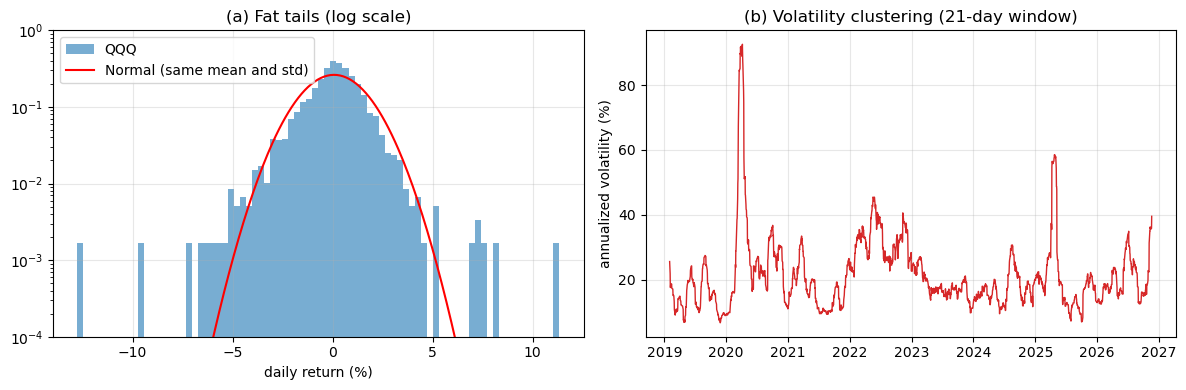

Skewness: -0.41   |   Excess kurtosis: 7.08  (Normal = 0)
ARCH-LM test p-value: 6.5e-80  (p < 0.05 means volatility clustering)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) Tails: real distribution vs a Normal with the same mean and std
x = np.linspace(r.min(), r.max(), 300)
ax[0].hist(r, bins=80, density=True, alpha=0.6, label="QQQ")
ax[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r", label="Normal (same mean and std)")
ax[0].set(yscale="log", ylim=(1e-4, 1), xlabel="daily return (%)", title="(a) Fat tails (log scale)")
ax[0].legend()

# (b) Volatility over time
ax[1].plot(r.rolling(21).std() * np.sqrt(DAYS), color="tab:red", lw=1)
ax[1].set(ylabel="annualized volatility (%)", title="(b) Volatility clustering (21-day window)")
show("fig1_qqq_returns")

print(f"Skewness: {stats.skew(r):.2f}   |   Excess kurtosis: {stats.kurtosis(r):.2f}  (Normal = 0)")
print(f"ARCH-LM test p-value: {het_arch(r - r.mean(), nlags=10)[1]:.1e}  (p < 0.05 means volatility clustering)")

**Analysis**
- **Fat tails.** Excess kurtosis is 7.08, while a Normal distribution has 0. In panel (a), the real tails lie far above the Normal curve, so extreme days are much more common than a Normal model says. The skewness of −0.41 also shows that big falls are larger than big rises.
- **Volatility clustering.** In panel (b), volatility is not constant: calm periods and turbulent periods come in groups (2020 and April 2025). The ARCH-LM test confirms that where as p < 0.05 means volatility clustering.

Therefore, a suitable model must let volatility change over time and must allow extreme shocks. Both matter more for a 3x ETF, because leverage magnifies them.

## 4. The Models
Every daily return can be split into an expected part and a random shock. The models differ in how they describe the size of the shock. We use two models (GBM and GARCH-t) and one model-free check (the historical bootstrap).

| Method | Type | Role |
|---|---|---|
| **GBM** | Model | Simple benchmark |
| **GARCH(1,1)-t** | Model | Main model |
| **Historical bootstrap** | No model | Reality check |

### 4.1 Model A: GBM (benchmark)
$$r_t = \mu + \sigma\, z_t, \qquad z_t \sim N(0,1)$$

Every day, the return is the same average plus a random shock. The shock always comes from the same bell curve, so **risk never changes**. This means the price follows a Geometric Brownian Motion (GBM), the classic model behind the Black-Scholes formula.

### 4.2 Model B: GARCH(1,1)-t (main model)
$$r_t = \mu + \varepsilon_t,\quad \varepsilon_t = \sigma_t z_t,\quad \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2,\quad z_t \sim \text{Student-}t(\nu)$$


### 4.1 Model A: GBM (benchmark)
$$r_t = \mu + \sigma\, z_t, \qquad z_t \sim N(0,1)$$

Each daily log return is a constant mean $\mu$ plus a Normal shock with constant standard deviation $\sigma$, so risk does not change over time. The implied price process is a Geometric Brownian Motion, the model underlying the Black-Scholes formula.

It is the standard simple model, but as Section 3 showed that QQQ volatility varies over time and its tails are heavier than Normal. GBM allows for neither.

### 4.2 Model B: GARCH(1,1)-t (main model)
$$r_t = \mu + \varepsilon_t,\quad \varepsilon_t = \sigma_t z_t,\quad \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2,\quad z_t \sim \text{Student-}t(\nu)$$

Here $\varepsilon_t$ is the unexpected part of the return and $\sigma_t^2$ is its variance, which is updated every day:

- $\omega$ is the base level of variance.
- $\alpha$ is the reaction to the previous day's shock: a large shock raises the next day's variance.
- $\beta$ is the carry-over of the previous day's variance: a high $\beta$ means volatility decays slowly.
- $\nu$ is the degrees of freedom of the Student-t distribution, which has heavier tails than the Normal. A smaller $\nu$ means heavier tails.

Large movements therefore tend to be followed by large movements, which is volatility clustering. 

It captures both features in Section 3, volatility clustering (through $\sigma_t^2$) and fat tails (through the t distribution). It can also start a simulation from the **current** volatility, which GBM cannot do. However, it is more complex and symmetric: shocks of equal size and opposite sign have the same effect on variance, whereas negative shocks usually raise volatility more in practice.

### 4.3 Method C: Historical bootstrap (check)
There is no parametric form. For each simulated day, one observed QQQ daily return is drawn at random with replacement, and 21 draws form one simulated month.

It makes no distributional assumption, so serves as a model-free check.

Section 5 estimates GBM and GARCH-t and tests which describes QQQ returns better.